In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

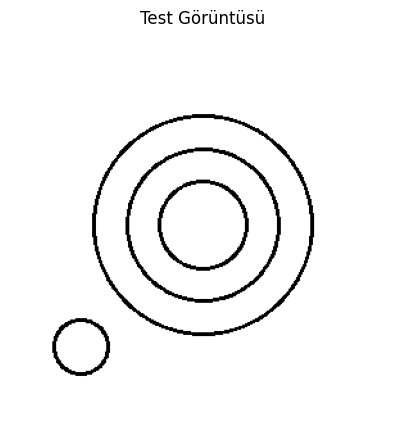

In [2]:
resim = np.full((300, 300, 3), 255, dtype=np.uint8)
merkez_gercek = (150, 150)
yaricaplar_gercek = [34, 59, 85]

for r in yaricaplar_gercek:
    cv2.circle(resim, merkez_gercek, r, (0, 0, 0), 2)
cv2.circle(resim, (55, 245), 21, (0, 0, 0), 2)

plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title('Test Görüntüsü')
plt.axis('off')
plt.show()

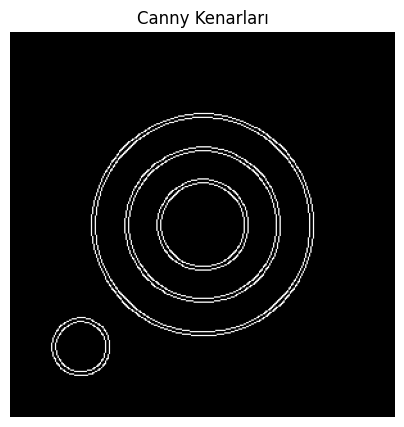

In [3]:
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)
kenarlar = cv2.Canny(gri, 60, 150)

plt.figure(figsize=(5, 5))
plt.imshow(kenarlar, cmap='gray')
plt.title('Canny Kenarları')
plt.axis('off')
plt.show()

In [4]:
acilar = np.deg2rad(np.arange(0, 360, 2))
sin_tablosu = np.sin(acilar)
cos_tablosu = np.cos(acilar)

yaricaplar = np.arange(15, 98)
ornek_yaricaplar = np.arange(14, 99)
yukseklik, genislik = kenarlar.shape

print('Açı sayısı:', len(acilar))
print('Aranan yarıçap sayısı:', len(yaricaplar))

Açı sayısı: 180
Aranan yarıçap sayısı: 83


In [5]:
kenar_var = (kenarlar > 0).astype(np.uint8)
cevre_destegi = np.zeros((len(ornek_yaricaplar), yukseklik, genislik), dtype=np.uint16)

for i, r in enumerate(ornek_yaricaplar):
    kaymalar = set()
    for c, s in zip(cos_tablosu, sin_tablosu):
        dx = int(np.rint(r * c))
        dy = int(np.rint(r * s))
        kaymalar.add((dx, dy))

    for dx, dy in kaymalar:
        x0, x1 = max(0, -dx), min(genislik, genislik - dx)
        y0, y1 = max(0, -dy), min(yukseklik, yukseklik - dy)
        if x0 >= x1 or y0 >= y1:
            continue
        cevre_destegi[i, y0:y1, x0:x1] += kenar_var[
            y0 + dy:y1 + dy, x0 + dx:x1 + dx
        ]

ic = cevre_destegi[yaricaplar - 1 - ornek_yaricaplar[0]].astype(np.int32)
dis = cevre_destegi[yaricaplar + 1 - ornek_yaricaplar[0]].astype(np.int32)
halka_destegi = np.minimum(ic, dis)

print('İki taraflı çevre oylaması tamamlandı:', halka_destegi.shape)

İki taraflı çevre oylaması tamamlandı: (83, 300, 300)


In [6]:
yerel_tepe = np.ones_like(halka_destegi, dtype=bool)
for fark in (1, 2, 3):
    yerel_tepe[fark:] &= (halka_destegi[fark:] >= halka_destegi[:-fark])
    yerel_tepe[:-fark] &= (halka_destegi[:-fark] >= halka_destegi[fark:])

kenar_esigi = int(np.ceil(0.35 * len(acilar)))
gecerli = (halka_destegi >= kenar_esigi) & yerel_tepe
min_yaricap_farki = 12

oylama = np.zeros((len(yaricaplar), yukseklik, genislik), dtype=np.int32)

for i, r1 in enumerate(yaricaplar):
    for j in range(i + 1, len(yaricaplar)):
        if yaricaplar[j] - r1 < min_yaricap_farki:
            continue
        birlikte_gecerli = gecerli[i] & gecerli[j]
        ortak_oy = np.where(
            birlikte_gecerli,
            halka_destegi[i] * halka_destegi[j],
            0
        )
        oylama[i] += ortak_oy
        oylama[j] += ortak_oy

print('3B ortak oylama matrisi:', oylama.shape)
print('En yüksek 3B oy:', int(oylama.max()))
print('Birlikte oy verme eşiği:', kenar_esigi)

3B ortak oylama matrisi: (83, 300, 300)
En yüksek 3B oy: 17184
Birlikte oy verme eşiği: 63


In [7]:
merkez_oylari = oylama.sum(axis=0)
y, x = np.unravel_index(np.argmax(merkez_oylari), merkez_oylari.shape)

r_oylari = oylama[:, y, x].copy()
esik = int(np.ceil(0.25 * r_oylari.max()))
bulunan_yaricaplar = []

while r_oylari.max() >= esik and r_oylari.max() > 0:
    i = int(np.argmax(r_oylari))
    r = int(yaricaplar[i])
    bulunan_yaricaplar.append(r)
    r_oylari[np.abs(yaricaplar - r) < 10] = 0

bulunan_yaricaplar.sort()
print('Bulunan merkez:', (int(x), int(y)))
print('Bulunan yarıçaplar:', bulunan_yaricaplar)
print('3B oylama eşiği:', esik)
print('Gerçek merkez:', merkez_gercek)
print('Gerçek yarıçaplar:', yaricaplar_gercek)
print('Bağımsız çember merkezinin ortak oy puanı:', int(merkez_oylari[245, 55]))

Bulunan merkez: (150, 150)
Bulunan yarıçaplar: [34, 59, 85]
3B oylama eşiği: 4296
Gerçek merkez: (150, 150)
Gerçek yarıçaplar: [34, 59, 85]
Bağımsız çember merkezinin ortak oy puanı: 0


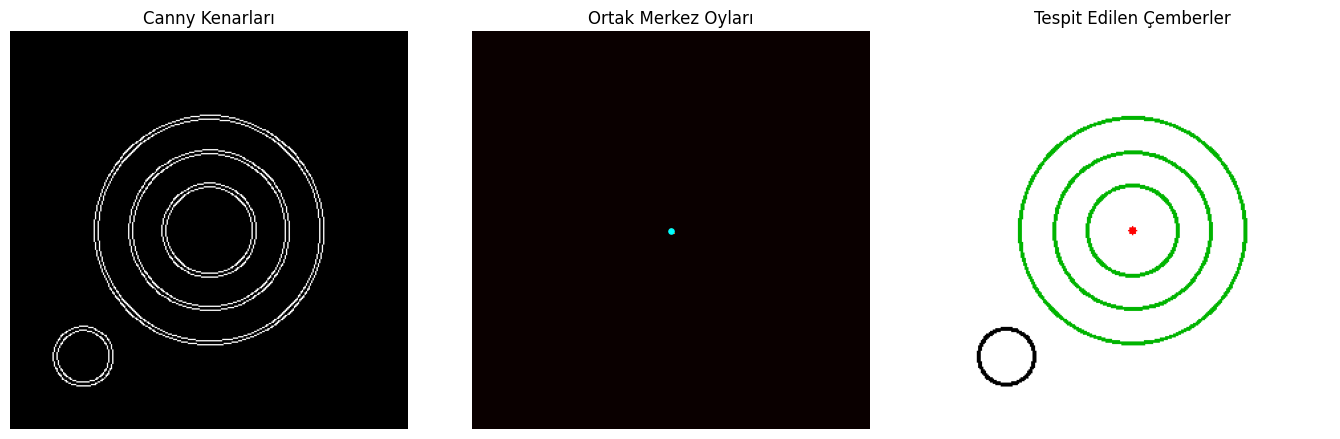

In [8]:
sonuc = resim.copy()
for r in bulunan_yaricaplar:
    cv2.circle(sonuc, (int(x), int(y)), r, (0, 180, 0), 2)
cv2.circle(sonuc, (int(x), int(y)), 3, (0, 0, 255), -1)

fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
ax[0].imshow(kenarlar, cmap='gray')
ax[0].set_title('Canny Kenarları')
ax[1].imshow(merkez_oylari, cmap='hot')
ax[1].scatter([x], [y], c='cyan', s=14)
ax[1].set_title('Ortak Merkez Oyları')
ax[2].imshow(cv2.cvtColor(sonuc, cv2.COLOR_BGR2RGB))
ax[2].set_title('Tespit Edilen Çemberler')
for a in ax: a.axis('off')
plt.tight_layout()
plt.show()